# Attention 注意力：从 Q、K、V 到手写 Self-Attention、Multi-Head 与 Transformer

注意力机制（Attention）让模型在处理一个位置时，动态决定应该从哪些位置读取信息、每个位置应读取多少。它最早用于 Seq2Seq 翻译中解决固定长度上下文向量的信息瓶颈，后来成为 Transformer、BERT、GPT、视觉 Transformer（ViT）和多模态模型的核心组件。

本文从“加权平均”这一最小直觉出发，逐步推导 Query、Key、Value（Q/K/V）、Scaled Dot-Product Attention、自注意力、多头注意力、交叉注意力、Padding Mask、Causal Mask，并使用 PyTorch 从零手写一个可训练的 Multi-Head Self-Attention。示例默认适用于 PyTorch 2.x：


In [1]:
import math
import torch
from torch import nn
import torch.nn.functional as F

In [2]:
torch.manual_seed(23)
device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f" 当前设备：{device}")

 当前设备：mps


In [8]:

# 如果当前任务更需要第 2 条信息，模型可以学习让它们的权重更大。最小代码例子：

values = torch.tensor([
    [1.0, 0.0],
    [0.0, 2.0],
    [3.0, 1.0],
])  # [L=3, D_v=2]

weights = torch.tensor([0.2, 0.7, 0.1])  # 所有权重非负，且和为 1
context = weights @ values

print(context)  # tensor([0.5, 1.5])
# 这里真正需要学习的是“当前应如何产生 `weights`”。Q/K/V 正是生成这些权重的机制。


tensor([0.5000, 1.5000])


In [13]:
## 3. 为什么 RNN 的固定上下文会成为瓶颈
# 因为rnn没有注意力机制，不知道哪些信息是重点哪些是不重要的内容，
# 下例用人为分数展示不同解码步骤可读取不同源位置：

encoder_states = torch.randn(1, 5, 8)  # [B=1, source_length=5, D=8]

# 假设生成目标第一个词更关注源位置 0；生成第二个词更关注源位置 3
scores_step_1 = torch.tensor([[4.0, 1.0, 0.0, -1.0, -2.0]])
scores_step_2 = torch.tensor([[-1.0, 0.0, 1.0, 4.0, -2.0]])

weights_1 = scores_step_1.softmax(dim=-1)
weights_2 = scores_step_2.softmax(dim=-1)
context_1 = weights_1.unsqueeze(1) @ encoder_states  # [1, 1, 8]
context_2 = weights_2.unsqueeze(1) @ encoder_states  # [1, 1, 8]

print(weights_1)
print(weights_2)

tensor([[0.9282, 0.0462, 0.0170, 0.0063, 0.0023]])
tensor([[0.0063, 0.0170, 0.0462, 0.9282, 0.0023]])


In [34]:
## 4. Attention 的三种角色：Query、Key、Value
# 注意力可类比为一次可检索的查询：
# - **Query（Q，查询）**：当前位置“我在寻找什么？”
# - **Key（K，键）**：每个候选位置“我能被怎样匹配？”
# - **Value（V，值）**：候选位置“被选中后，我提供什么信息？”

# query 就是要查询的东西
query = torch.tensor([1.0, 0.0])
# key 表示我的数据是这样的，等待其他q张量来计算得到某个结果s
keys = torch.tensor([
    [1.0, 0.0],
    [0.0, 1.0],
    [0.5, 0.5],
])
# value 表示道歉存储到权重数据，如果当前位置被选中，那么这个 value 将会被用于计算注意力
values = torch.tensor([
    [10.0],
    [20.0],
    [30.0],
])

print(query.shape, keys.shape, keys.T.shape) # (torch.Size([2]), torch.Size([3, 2]), torch.Size([2, 3]))
s = query @ keys.T
print(f"s.shape {s.shape}, s: {s}") # [3]

weights = F.softmax(s, dim=-1)
print(f"weights.shape {weights.shape}, weights: {weights}")

attention = weights @ values
print(f"attention.shape {attention.shape}, attention: {attention}")


def attention(query, keys, values):
    s = query @ keys.T
    weights = F.softmax(s, dim=-1)
    context = weights @ values
    return context

print(f"function attention: {attention(query, keys, values)}")


torch.Size([2]) torch.Size([3, 2]) torch.Size([2, 3])
s.shape torch.Size([3]), s: tensor([1.0000, 0.0000, 0.5000])
weights.shape torch.Size([3]), weights: tensor([0.5065, 0.1863, 0.3072])
attention.shape torch.Size([1]), attention: tensor([18.0072])
function attention: tensor([18.0072])


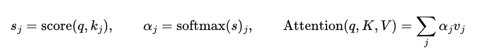

In [37]:
## 5. 点积为什么能作为相似度分数
def cul_score(query, keys):
    return query @ keys.T
    # return query.T @ keys

print(f"function cul_score: {cul_score(query, keys)}")


function cul_score: tensor([1.0000, 0.0000, 0.5000])


In [45]:
## 6. Softmax：把任意分数变成注意力权重
# 点积结果可正可负，且不保证和为 1。这时就需要使用 softmax 将它变成概率分布：
w = F.softmax(cul_score(query, keys), dim=-1)
print(f"softmax(query, keys): {w}")
print(f"sum softmax: {w.sum()}")

x = torch.randn(5)
print(f"x.shape {x.shape}, x: {x}")
w = F.softmax(x, dim=-1)
print(f"w.shape {w.shape}, w: {w}")
print(f"softmax(x, keys): {w.sum()}")

# 在 batch 注意力中，softmax 必须沿“key 位置”维度做归一化。对于分数 `[B, Lq, Lk]`，使用 `dim=-1`，一般情况下都是使用-1，表示对最内层的概率使用 softmax 进行计算
scores = torch.randn(2, 3, 5)  # B=2，3个 query，各自匹配 5 个 key
weights = torch.softmax(scores, dim=-1) # weight 最后一维Lk里面每一个位置存储到是scores对应的softmax之后的分数了
print(weights.shape)             # [2, 3, 5]
print(weights[0, 0].sum())       # 1：一个 query 对全部 key 的权重和

softmax(query, keys): tensor([0.5065, 0.1863, 0.3072])
sum softmax: 1.0
x.shape torch.Size([5]), x: tensor([ 1.2675,  0.7871, -1.9426,  1.3427,  0.2431])
w.shape torch.Size([5]), w: tensor([0.3230, 0.1998, 0.0130, 0.3482, 0.1160])
softmax(x, keys): 1.0
torch.Size([2, 3, 5])
tensor(1.)


In [48]:
## 7. 先手写单头注意力：无 batch 版本
# 设有 `Lq` 个 query、`Lk` 个 key/value：
def attention_no_batch(query, keys, values):
    """
    :param query: [Lq, Dk]
    :param keys: [Lk, Dk]
    :param values: [Lk, Dv]
    :return:
      output: [Lq, Dv],
      weights: [Lq, Lk]
    """
    s = query @ keys.T
    weights = F.softmax(s, dim=-1)
    context = weights @ values
    return context, weights

q = torch.randn(2, 4)
k = torch.randn(3, 4)
v = torch.randn(3, 6)
output, weights = attention_no_batch(q, k, v)
print(output.shape)   # [2, 6]
print(weights.shape)  # [2, 3]



torch.Size([2, 6])
torch.Size([2, 3])


In [55]:

## 8. Batch Attention 的 shape 推导
"""
实际训练通常有 batch 维度。令：
Q: [B, Lq, Dk]
K: [B, Lk, Dk]
V: [B, Lk, Dv]

使用 `K.transpose(-2, -1)` 后：
K^T: [B, Dk, Lk]
Q @ K^T: [B, Lq, Lk]
weights @ V: [B, Lq, Dv]
"""
def batch_dot_product_attention(q, k, v):
    s = q @ k.transpose(-1, -2)
    weights = F.softmax(s, dim=-1)
    context = weights @ v
    return context, weights

q = torch.randn(2, 4, 8)
k = torch.randn(2, 6, 8)
v = torch.randn(2, 6, 10)
output, weights = batch_dot_product_attention(q, k, v)
print(output.shape)
print(weights.shape)


torch.Size([2, 4, 10])
torch.Size([2, 4, 6])


In [56]:
# 1. PyTorch 内置的 Attention 模块
# API	类型	主要用途
# nn.MultiheadAttention	多头注意力模块	Transformer 的核心 Attention
# F.scaled_dot_product_attention	缩放点积注意力函数	实现 Attention 的核心计算
# nn.TransformerEncoderLayer	Transformer Encoder 层	自注意力 + FFN
# nn.TransformerDecoderLayer	Transformer Decoder 层	自注意力 + 交叉注意力 + FFN
# nn.TransformerEncoder	Encoder 堆叠模块	多层 Transformer Encoder
# nn.TransformerDecoder	Decoder 堆叠模块	多层 Transformer Decoder
#
# 另外，PyTorch 还提供了 FlexAttention 等更灵活的底层构建组件。


In [58]:
# ① nn.MultiheadAttention
# 这是 PyTorch 内置的多头注意力模块，实现了 Transformer 原论文中的 Multi-Head Attention。
attention = nn.MultiheadAttention(
    embed_dim=128, # 嵌入向量的维度
    num_heads=8, # 多头注意力机制的头数
    dropout=0.1, # 丢弃率
    batch_first=True # 是否把batch维度放到第一个位置
)
# head组件的维度head_dim = embed_dim/num_heads

# 假设输入为 [batch_size, seq_len, embedding_dim]
x = torch.randn(32, 100, 128)

output, attention_weights = attention(
    query=x,
    key=x,
    value=x
)

print(output.shape)
print(attention_weights.shape)


4.0
torch.Size([32, 100, 128])
torch.Size([32, 100, 100])


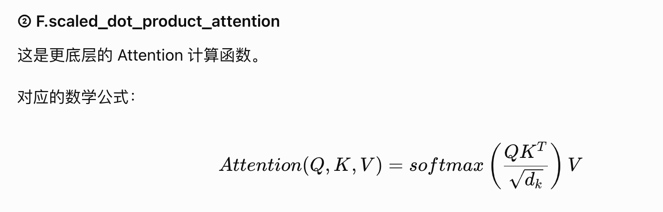

In [59]:
Q = torch.randn(32, 8, 100, 64)
K = torch.randn(32, 8, 100, 64)
V = torch.randn(32, 8, 100, 64)

output = F.scaled_dot_product_attention(
    Q, K, V
)

print(output.shape)
# [32, 8, 100, 64]

torch.Size([32, 8, 100, 64])


In [60]:
# ③ nn.TransformerEncoderLayer
# 这是已经封装好的一个 Transformer Encoder Block。
# 输入 -> Multi-Head Self-Attention -> 残差连接 + LayerNorm -> Feed Forward Network -> 残差连接 + LayerNorm -> 输出
encoder_layer = nn.TransformerEncoderLayer(
    d_model=128, # 输入和输出特征的维度
    nhead=8, # 多头注意力机制的头数
    dim_feedforward=512, # 前馈神经网络中间层的维度
    dropout=0.1, # 	Dropout 随机失活概率
    batch_first=True # 输入张量是否采用 Batch 优先格式
)

x = torch.randn(32, 100, 128)

output = encoder_layer(x)

print(output.shape)
# [32, 100, 128]
